# Lab 01 — Descriptive Statistics in Python
**Department of Applied Mathematics and Statistics (AMS), Institute of Technology of Cambodia**
Asst. Prof. Dr. PHAUK Sokkhey

---

### Learning objectives
By the end of this lab you will be able to:
1. Classify variables as **nominal, ordinal, interval, or ratio**.
2. Compute and interpret **mean, median, mode, range, variance, standard deviation, IQR, CV, skewness and kurtosis** using built-in functions.
3. Build a **five-number summary**, detect outliers with the $1.5\times\text{IQR}$ rule, and draw a **boxplot**.
4. Summarise **categorical data** with a frequency table (frequency, percent, cumulative percent).

### Lab structure
| Part | Content | Status |
|---|---|---|
| A — Exercise 1 | Tensile strength of steel specimens (quantitative data) | Solved |
| A — Exercise 2 | Salaries of Company A vs B + marital-status table | Solved |
| B — Practice 1 | Test scores in English, Math, Physics | `# TODO` |
| B — Practice 2 | Defect types and customer ratings on a production line | `# TODO` |

### Formula reference (from Lecture 01)

| Measure | Population | Sample | Python |
|---|---|---|---|
| Mean | $\mu=\dfrac{\sum x_i}{N}$ | $\bar x=\dfrac{\sum x_i}{n}$ | `s.mean()` |
| Variance | $\sigma^2=\dfrac{\sum (x_i-\mu)^2}{N}$ | $s^2=\dfrac{\sum (x_i-\bar x)^2}{n-1}$ | `s.var(ddof=0)` / `s.var()` |
| Std. deviation | $\sigma=\sqrt{\sigma^2}$ | $s=\sqrt{s^2}$ | `s.std(ddof=0)` / `s.std()` |
| Coefficient of variation | | $CV=\dfrac{s}{\bar x}\times100\%$ | `s.std()/s.mean()*100` |
| IQR | | $Q_3-Q_1$ | `s.quantile(.75)-s.quantile(.25)` |
| Pearson skewness | | $Sk=\dfrac{3(\bar x-\text{median})}{s}$ | — |
| Kurtosis | | normal $=3$ (excess $=0$) | `stats.kurtosis(x, fisher=False)` |

> ⚠️ **Watch the defaults:** `pandas` uses `ddof=1` (sample), `numpy` uses `ddof=0` (population). `pandas.Series.kurt()` returns **excess** kurtosis (normal $=0$), not the lecture's scale (normal $=3$).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.precision", 3)
plt.rcParams["figure.figsize"] = (8, 4)

---
# Part A — Worked Exercises (with Solutions)

## Exercise 1 — Tensile Strength of Steel Specimens
A materials lab tested 20 steel rods. Tensile strength (MPa) is recorded below.
The last specimen was mis-recorded during data entry (an **outlier**).

**Tasks**
1. Identify the level of measurement of `strength`.
2. Compute mean, median, mode.
3. Compute range, sample variance, sample SD, CV, and IQR.
4. Build the five-number summary, find outliers with the $1.5\times\text{IQR}$ rule, and draw a boxplot.
5. Compute skewness and kurtosis and interpret the shape.
6. Remove the outlier and compare: which measures are **robust**?

In [2]:
strength = pd.Series([412, 425, 418, 430, 421, 415, 428, 419, 433, 422,
                      417, 426, 420, 424, 431, 418, 423, 427, 416, 610],
                     name="strength_MPa")
strength.describe()

count     20.000
mean     431.750
std       42.337
min      412.000
25%      418.000
50%      422.500
75%      427.250
max      610.000
Name: strength_MPa, dtype: float64

**1. Level of measurement.** Tensile strength has a true zero (0 MPa = no strength) and ratios are meaningful (400 MPa is twice 200 MPa) → **ratio**, quantitative, continuous.

**2. Measures of central tendency**

In [3]:
center = pd.Series({
    "Mean":   strength.mean(),
    "Median": strength.median(),
    "Mode":   strength.mode().tolist(),
})
center

Mean      431.75
Median     422.5
Mode       [418]
dtype: object

The mean (≈ 431.8) is pulled above the median (422.5) by the 610 MPa outlier. The mode (418) is not very informative for continuous data.

**3. Measures of variability**

In [4]:
Q1, Q3 = strength.quantile([0.25, 0.75])
spread = pd.Series({
    "Range":            strength.max() - strength.min(),
    "Variance (s^2)":   strength.var(),           # ddof=1 → sample
    "Variance (σ^2)":   strength.var(ddof=0),     # population
    "SD (s)":           strength.std(),
    "CV (%)":           strength.std() / strength.mean() * 100,
    "IQR":              Q3 - Q1,
})
spread

Range              198.000
Variance (s^2)    1792.408
Variance (σ^2)    1702.787
SD (s)              42.337
CV (%)               9.806
IQR                  9.250
dtype: float64

**4. Five-number summary, outlier fences, boxplot**

Lower fence $=Q_1-1.5\,\text{IQR}$, Upper fence $=Q_3+1.5\,\text{IQR}$.

Min       412.00
Q1        418.00
Median    422.50
Q3        427.25
Max       610.00
dtype: float64 
Fences: [404.12, 441.12]
Outliers: [610]


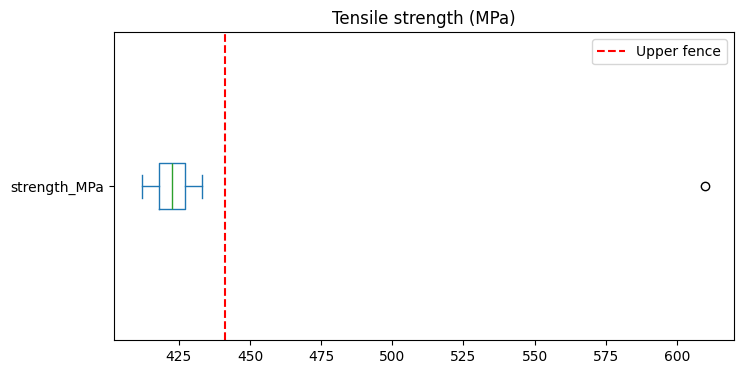

In [5]:
IQR = Q3 - Q1
lower, upper = Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

five_num = pd.Series({"Min": strength.min(), "Q1": Q1, "Median": strength.median(),
                      "Q3": Q3, "Max": strength.max()})
print(five_num, f"\nFences: [{lower:.2f}, {upper:.2f}]")
print("Outliers:", strength[(strength < lower) | (strength > upper)].tolist())

strength.plot.box(vert=False, title="Tensile strength (MPa)")
plt.axvline(upper, ls="--", c="red", label="Upper fence"); plt.legend(); plt.show()

**5. Shape: skewness and kurtosis**

In [6]:
shape = pd.Series({
    "Pearson skew 3(mean-median)/s": 3 * (strength.mean() - strength.median()) / strength.std(),
    "Moment skew (scipy)":           stats.skew(strength),
    "Kurtosis (normal = 3)":         stats.kurtosis(strength, fisher=False),
    "Excess kurtosis (pandas)":      strength.kurt(),
})
shape

Pearson skew 3(mean-median)/s     0.655
Moment skew (scipy)               4.007
Kurtosis (normal = 3)            17.417
Excess kurtosis (pandas)         19.171
dtype: float64

**Interpretation.** Moment skewness ≈ 4 $>1$ → **highly right-skewed**. Kurtosis ≈ 17 $\gg 3$ → **leptokurtic** (heavy tail), driven entirely by one extreme value.

> Note that Pearson's formula gives only ≈ 0.66 here: it uses the median, which ignores the extreme value, so it *understates* skewness caused by a single outlier. Software (`scipy`, `pandas`, Excel `SKEW`) uses the moment-based definition.

**6. Effect of removing the outlier**

In [7]:
clean = strength[strength.between(lower, upper)]
compare = pd.DataFrame({
    "With outlier":    [strength.mean(), strength.median(), strength.std(), Q3 - Q1, stats.skew(strength)],
    "Without outlier": [clean.mean(), clean.median(), clean.std(),
                        clean.quantile(.75) - clean.quantile(.25), stats.skew(clean)],
}, index=["Mean", "Median", "SD", "IQR", "Skewness"])
compare["Change"] = compare["Without outlier"] - compare["With outlier"]
compare

,With outlier,Without outlier,Change
Mean,431.750,422.368,-9.382
Median,422.500,422.000,-0.500
SD,42.337,5.823,-36.513
IQR,9.250,8.500,-0.750
Skewness,4.007,0.141,-3.866


**Conclusion.** One bad value moved the mean by ≈ 9.4 MPa and inflated the SD about seven-fold (5.8 → 42.3), while the **median and IQR barely changed** — they are *robust* measures. For engineering QC data with possible recording errors, report the median and IQR alongside the mean and SD.

---
## Exercise 2 — "The Deceptive Average" + Categorical Summary

### 2a. Company A vs Company B
Both companies report a mean salary of \$70,000 (Lecture slide *Central Tendency*).
- Company A: 50 employees each earn \$70,000.
- Company B: 25 earn \$35,000 and 25 earn \$105,000.

**Tasks:** Compare mean, median, SD, CV and range. Which company would you join?

In [8]:
salary = pd.DataFrame({
    "Company A": np.repeat(70_000, 50),
    "Company B": np.repeat([35_000, 105_000], 25),
})

summary = salary.agg(["mean", "median", "std", "min", "max"]).T
summary["CV (%)"] = summary["std"] / summary["mean"] * 100
summary["Range"]  = summary["max"] - summary["min"]
summary

,mean,median,std,min,max,CV (%),Range
Company A,70000.0,70000.0,0.000,70000.0,70000.0,0.000,0.0
Company B,70000.0,70000.0,35355.339,35000.0,105000.0,50.508,70000.0


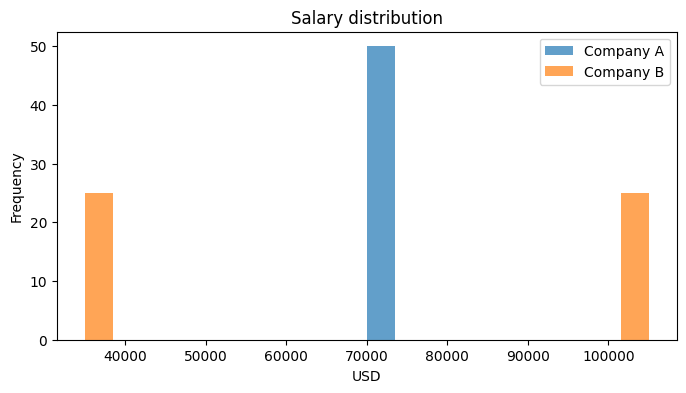

In [9]:
salary.plot.hist(bins=20, alpha=0.7, title="Salary distribution"); plt.xlabel("USD"); plt.show()

**Interpretation.** Same mean and median, but Company A has SD = 0 while Company B has SD ≈ \$35,355 (CV ≈ 50%). A new employee at B has a 50% chance of earning only half the "average". Note also that B's median (\$70,000) is the average of the two middle values — **no one at B actually earns it**. **A measure of center is incomplete without a measure of spread.**

### 2b. Frequency table for a nominal variable
Reproduce the lecture's marital-status table for a sample of 80 people.

In [9]:
marital = pd.Series(["Single"] * 44 + ["Married"] * 29 + ["Other"] * 7, name="Marital status")

freq = marital.value_counts().to_frame("Frequency")
freq["Percent"]            = marital.value_counts(normalize=True) * 100
freq["Cumulative Percent"] = freq["Percent"].cumsum()
freq.loc["Total"] = [freq["Frequency"].sum(), 100, np.nan]
freq.astype({"Frequency": int}).round(1)

,Frequency,Percent,Cumulative Percent
Marital status,,,
Single,44,55.0,55.0
Married,29,36.2,91.2
Other,7,8.8,100.0
Total,80,100.0,NaN


Mode: Single


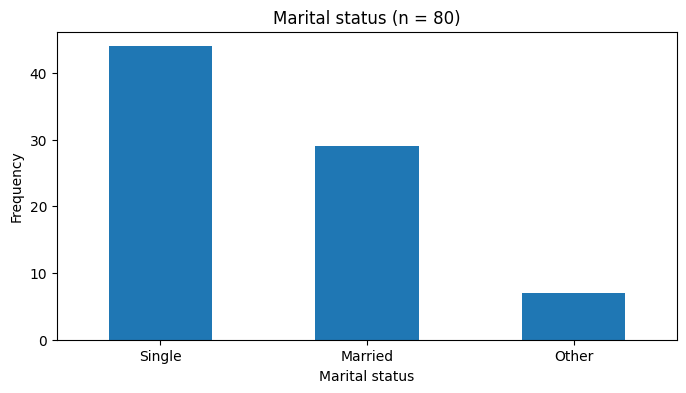

In [10]:
print("Mode:", marital.mode()[0])
marital.value_counts().plot.bar(rot=0, title="Marital status (n = 80)"); plt.ylabel("Frequency"); plt.show()

**Note.** For a **nominal** variable, the mean and median are meaningless; the **mode** and the frequency/percent table are the appropriate summaries.

---
# Part B — Practice Exercises (Complete the `# TODO` cells)

## Practice 1 — Test Scores in Three Subjects
This mirrors the lecture slide *Standard Deviation Interpretation*. Scores for 300 students are generated below (do **not** change the seed).

**Tasks**
1. Compute mean, median, SD, CV, IQR, skewness and kurtosis (normal = 3) for each subject in **one table**.
2. Draw side-by-side boxplots and histograms.
3. List the outliers in each subject using the $1.5\times\text{IQR}$ rule.
4. Answer: *What does the SD tell you about students' performance in each test?*

In [11]:
rng = np.random.default_rng(2026)
scores = pd.DataFrame({
    "English": rng.normal(100, 7.5, 300).round(1),
    "Math":    rng.normal(100, 15.3, 300).round(1),
    "Physics": rng.normal(100, 30.8, 300).round(1),
})
scores.head()

,English,Math,Physics
0,94.1,100.7,128.3
1,101.8,84.1,96.2
2,85.8,116.6,122.2
3,110.5,124.5,49.0
4,104.8,101.0,91.9


In [12]:
# TODO 1: Build a summary table with one row per subject and columns
#         Mean, Median, SD, CV (%), IQR, Skewness, Kurtosis (normal = 3)
# Hint: scores.agg([...]) and scores.quantile([...]); stats.kurtosis(..., fisher=False)
Q1, Q3 = scores.quantile([25, 75])

# spread = pd.Series({
#     "Range":            strength.max() - strength.min(),
#     "Variance (s^2)":   strength.var(),           # ddof=1 → sample
#     "Variance (σ^2)":   strength.var(ddof=0),     # population
#     "SD (s)":           strength.std(),
#     "CV (%)":           strength.std() / strength.mean() * 100,
#     "IQR":              Q3 - Q1,
# })

summary_scores = pd.Series({
    "Mean":         scores.mean(),
    "Median":       scores.median(),
    "SD":           scores.std(),
    "CV":           scores.std() / scores.mean() * 100,
    # "IQR":          Q3 - Q1,
    "Skewness":     scores.quantile(),
    "Kurtosis":     scores.kurtosis()
})
summary_scores

ValueError: percentiles should all be in the interval [0, 1]

In [ ]:
# TODO 2: Side-by-side boxplots (one figure) and overlaid histograms (another figure)
# Hint: scores.plot.box(...), scores.plot.hist(alpha=..., bins=...)

In [ ]:
# TODO 3: For each subject compute Q1, Q3, IQR, the fences and print the outlier values
# Hint: loop over scores.columns, or use scores.quantile([.25, .75])

**TODO 4 — Interpretation (write 3–4 sentences):**

*Your answer here.*

---
## Practice 2 — Quality Control on a Production Line
An inspector recorded each defective unit's **defect type** (nominal) and the customer's **rating** of the replacement service (ordinal: *Bad < Good < Excellent*).

**Tasks**
1. State the level of measurement of each variable.
2. Build a frequency table for `defect` with Frequency, Percent and Cumulative Percent, **sorted from most to least frequent** (a Pareto table).
3. Find the mode of each variable and draw a bar chart of `defect`.
4. Convert `rating` to an **ordered categorical** and find its median category.
5. Answer: *Why can we report a median for `rating` but not for `defect`?*

In [ ]:
rng = np.random.default_rng(15)
qc = pd.DataFrame({
    "defect": rng.choice(["Scratch", "Crack", "Misalignment", "Porosity", "Dent"],
                         size=120, p=[0.35, 0.10, 0.25, 0.20, 0.10]),
    "rating": rng.choice(["Bad", "Good", "Excellent"], size=120, p=[0.2, 0.5, 0.3]),
})
qc.head()

**TODO 1 — Level of measurement:**
- `defect`: *...*
- `rating`: *...*

In [ ]:
# TODO 2: Pareto frequency table for qc["defect"]
# Hint: value_counts(), value_counts(normalize=True), cumsum()

pareto = ...
pareto

In [ ]:
# TODO 3: Mode of each variable + bar chart of defect frequencies

In [ ]:
# TODO 4: Make rating an ordered categorical, then find the median category
# Hint: pd.Categorical(..., categories=["Bad", "Good", "Excellent"], ordered=True)
#       the median of the category codes → map back to a label

**TODO 5 — Interpretation:**

*Your answer here.*

---
### Submission
Run **Kernel → Restart & Run All**, make sure every cell executes without error, and submit the `.ipynb` file.